
===== CIFAR10 (ViT) =====
Batch | PromptMIA Adv (mean±std) | PromptMIA ASR (mean±std) | Naive Adv (mean±std) | Naive ASR (mean±std)
---------------------------------------------------------------------------------------------------------
    1 | 100.00± 0.00 | 100.00± 0.00 |  99.06± 0.05 |  99.53± 0.02
    4 |  99.81± 0.06 |  99.90± 0.03 |  96.20± 0.21 |  98.10± 0.11
    8 |  99.59± 0.04 |  99.80± 0.02 |  92.85± 0.17 |  96.42± 0.08
   16 |  99.15± 0.05 |  99.57± 0.03 |  86.54± 0.21 |  93.27± 0.11
   32 |  98.39± 0.08 |  99.19± 0.04 |  76.69± 0.47 |  88.35± 0.24
   64 |  97.17± 0.14 |  98.58± 0.07 |  63.14± 0.28 |  81.57± 0.14
  128 |  95.46± 0.32 |  97.73± 0.16 |  47.79± 0.29 |  73.89± 0.15
  256 |  93.23± 0.24 |  96.62± 0.12 |  32.24± 0.29 |  66.12± 0.14

===== CIFAR100 (ViT) =====
Batch | PromptMIA Adv (mean±std) | PromptMIA ASR (mean±std) | Naive Adv (mean±std) | Naive ASR (mean±std)
---------------------------------------------------------------------------------------------------

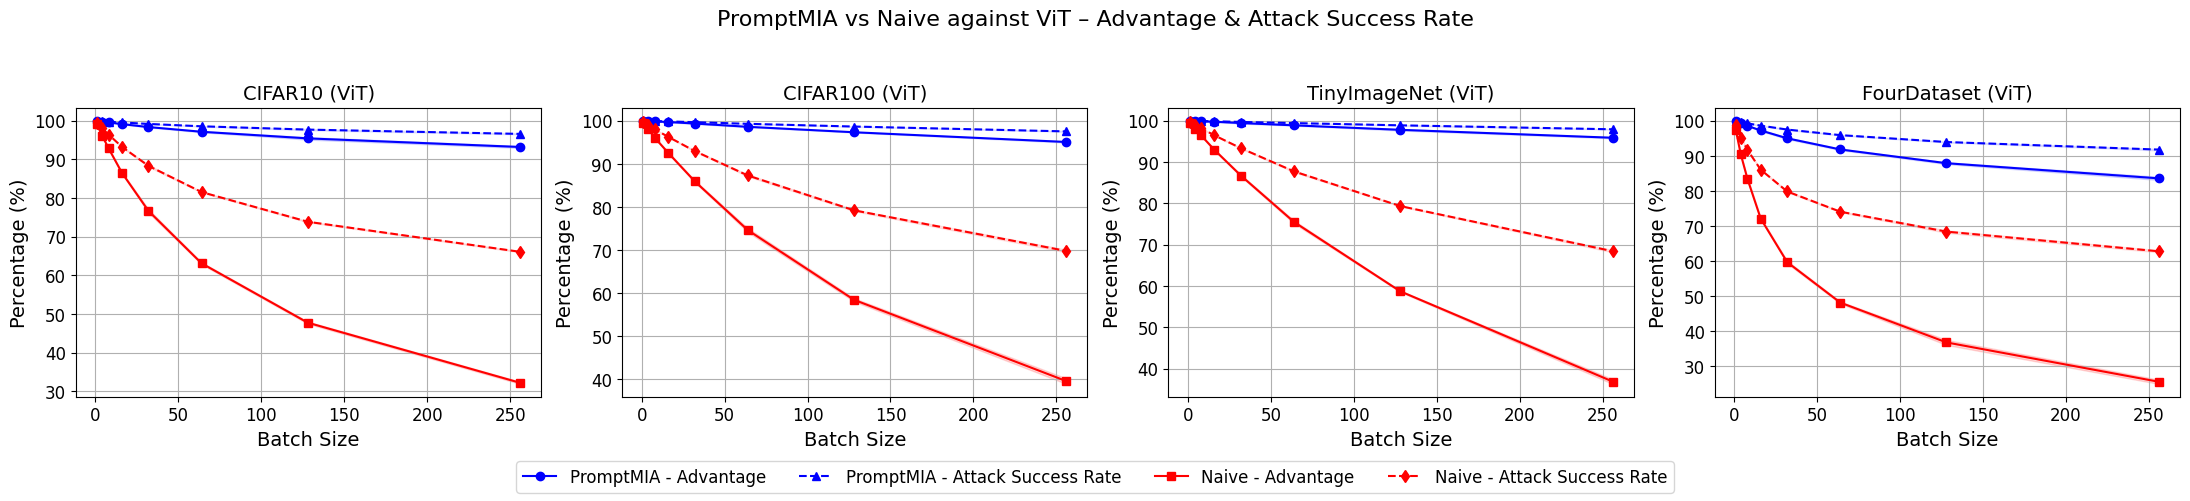

In [6]:

import re
from pathlib import Path
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
# ---------------- Regex patterns ----------------
BATCH_HEADER_RE = re.compile(r"=+\s*MIA with batch size\s+(\d+)\s*=+")
ADV_RE = re.compile(r"Advantage:\s*([0-9]*\.?[0-9]+)\s*%")
ACC_RE = re.compile(r"Attack Accuracy:\)\s*([0-9]*\.?[0-9]+)\s*%")

# ---------------- Parsing ----------------
def parse_log_file(path: str):
    text = Path(path).read_text(errors="ignore")

    adv_vals = defaultdict(list)
    acc_vals = defaultdict(list)

    headers = list(BATCH_HEADER_RE.finditer(text))
    if not headers:
        raise ValueError(f"No batch headers found in: {path}")

    for i, m in enumerate(headers):
        bs = int(m.group(1))
        start = m.end()
        end = headers[i + 1].start() if i + 1 < len(headers) else len(text)
        block = text[start:end]

        adv_m = ADV_RE.search(block)
        acc_m = ACC_RE.search(block)

        if adv_m:
            adv_vals[bs].append(float(adv_m.group(1)))
        if acc_m:
            acc_vals[bs].append(float(acc_m.group(1)))

    batches = sorted(set(adv_vals) & set(acc_vals))
    if not batches:
        raise ValueError(f"No valid batches in: {path}")

    adv_mean = [np.mean(adv_vals[b]) for b in batches]
    adv_std  = [np.std(adv_vals[b], ddof=0) for b in batches]
    acc_mean = [np.mean(acc_vals[b]) for b in batches]
    acc_std  = [np.std(acc_vals[b], ddof=0) for b in batches]

    return batches, adv_mean, adv_std, acc_mean, acc_std


def reindex(batches_src, arr_src, common_batches):
    idx = {b: i for i, b in enumerate(batches_src)}
    return [arr_src[idx[b]] for b in common_batches]


# ---------------- Pretty printing ----------------
def print_results(dataset_name, d):
    print(f"\n===== {dataset_name} (ViT) =====")
    header = (
        "Batch | "
        "PromptMIA Adv (mean±std) | PromptMIA ASR (mean±std) | "
        "Naive Adv (mean±std) | Naive ASR (mean±std)"
    )
    print(header)
    print("-" * len(header))

    for i, b in enumerate(d["batch_sizes"]):
        print(
            f"{b:5d} | "
            f"{d['promptmia_adv'][i]:6.2f}±{d['promptmia_adv_std'][i]:5.2f} | "
            f"{d['promptmia_acc'][i]:6.2f}±{d['promptmia_acc_std'][i]:5.2f} | "
            f"{d['naive_adv'][i]:6.2f}±{d['naive_adv_std'][i]:5.2f} | "
            f"{d['naive_acc'][i]:6.2f}±{d['naive_acc_std'][i]:5.2f}"
        )


# ---------------- Main ----------------
def main():
    files = {
        "CIFAR10": {
            "promptmia": "/home/quannm/code/icml_promptmia/result_log/cifar10_vit_stealth.txt",
            "naive":     "/home/quannm/code/icml_promptmia/result_log/cifar10_vit_naive.txt",
        },
        "CIFAR100": {
            "promptmia": "/home/quannm/code/icml_promptmia/result_log/cifar100_vit_stealth.txt",
            "naive":     "/home/quannm/code/icml_promptmia/result_log/cifar100_vit_naive.txt",
        },
        "TinyImageNet": {
            "promptmia": "/home/quannm/code/icml_promptmia/result_log/tinyimagenet_vit_stealth.txt",
            "naive":     "/home/quannm/code/icml_promptmia/result_log/tinyimagenet_vit_naive.txt",
        },
        "FourDataset": {
            "promptmia": "/home/quannm/code/icml_promptmia/result_log/fourdataset_vit_stealth.txt",
            "naive":     "/home/quannm/code/icml_promptmia/result_log/fourdataset_vit_naive.txt",
        },
    }
    parsed = {}

    for name, paths in files.items():
        bs_p, adv_p, adv_p_std, acc_p, acc_p_std = parse_log_file(paths["promptmia"])
        bs_n, adv_n, adv_n_std, acc_n, acc_n_std = parse_log_file(paths["naive"])

        common_bs = sorted(set(bs_p) & set(bs_n))
        if not common_bs:
            raise ValueError(f"No overlapping batch sizes for {name}")

        parsed[name] = {
            "batch_sizes": common_bs,

            "promptmia_adv":     reindex(bs_p, adv_p, common_bs),
            "promptmia_adv_std": reindex(bs_p, adv_p_std, common_bs),
            "promptmia_acc":     reindex(bs_p, acc_p, common_bs),
            "promptmia_acc_std": reindex(bs_p, acc_p_std, common_bs),

            "naive_adv":         reindex(bs_n, adv_n, common_bs),
            "naive_adv_std":     reindex(bs_n, adv_n_std, common_bs),
            "naive_acc":         reindex(bs_n, acc_n, common_bs),
            "naive_acc_std":     reindex(bs_n, acc_n_std, common_bs),
        }

        # 🔹 Print numerical results
        print_results(name, parsed[name])

    # ---------------- Plot ----------------
    fig, axes = plt.subplots(1, 4, figsize=(22, 5))
    handles, labels = None, None

    for ax, (name, d) in zip(axes.flat, parsed.items()):
        bs = d["batch_sizes"]

        ax.plot(bs, d["promptmia_adv"], "o-", color="blue", label="PromptMIA - Advantage")
        ax.fill_between(
            bs,
            np.array(d["promptmia_adv"]) - np.array(d["promptmia_adv_std"]),
            np.array(d["promptmia_adv"]) + np.array(d["promptmia_adv_std"]),
            color="blue", alpha=0.15
        )

        ax.plot(bs, d["promptmia_acc"], "^--", color="blue", label="PromptMIA - Attack Success Rate")
        ax.fill_between(
            bs,
            np.array(d["promptmia_acc"]) - np.array(d["promptmia_acc_std"]),
            np.array(d["promptmia_acc"]) + np.array(d["promptmia_acc_std"]),
            color="blue", alpha=0.10
        )

        ax.plot(bs, d["naive_adv"], "s-", color="red", label="Naive - Advantage")
        ax.fill_between(
            bs,
            np.array(d["naive_adv"]) - np.array(d["naive_adv_std"]),
            np.array(d["naive_adv"]) + np.array(d["naive_adv_std"]),
            color="red", alpha=0.15
        )

        ax.plot(bs, d["naive_acc"], "d--", color="red", label="Naive - Attack Success Rate")
        ax.fill_between(
            bs,
            np.array(d["naive_acc"]) - np.array(d["naive_acc_std"]),
            np.array(d["naive_acc"]) + np.array(d["naive_acc_std"]),
            color="red", alpha=0.10
        )

        ax.set_title(f"{name} (ViT)", fontsize=14)
        ax.set_xlabel("Batch Size", fontsize=14)
        ax.set_ylabel("Percentage (%)", fontsize=14)
        ax.yaxis.set_major_locator(MultipleLocator(10))
        ax.tick_params(axis="both", labelsize=12)
        ax.grid(True)

        if handles is None and labels is None:
            handles, labels = ax.get_legend_handles_labels()

    fig.legend(handles, labels, loc="lower center", fontsize=12, ncol=4)
    plt.suptitle(
        "PromptMIA vs Naive against ViT – Advantage & Attack Success Rate",
        fontsize=16
    )
    plt.tight_layout(rect=[0, 0.07, 1, 0.93])
    plt.show()


if __name__ == "__main__":
    main()



===== CIFAR10 (ConViT) =====
Batch | PromptMIA Adv (mean±std) | PromptMIA ASR (mean±std) | Naive Adv (mean±std) | Naive ASR (mean±std)
---------------------------------------------------------------------------------------------------------
    1 | 100.00± 0.00 | 100.00± 0.00 |  99.33± 0.07 |  99.67± 0.04
    4 |  99.96± 0.02 |  99.98± 0.01 |  97.48± 0.17 |  98.74± 0.09
    8 |  99.87± 0.02 |  99.93± 0.01 |  95.00± 0.32 |  97.50± 0.16
   16 |  99.71± 0.07 |  99.86± 0.03 |  90.09± 0.12 |  95.04± 0.06
   32 |  99.57± 0.06 |  99.78± 0.03 |  82.76± 0.44 |  91.38± 0.22
   64 |  99.04± 0.08 |  99.52± 0.04 |  71.10± 0.73 |  85.55± 0.37
  128 |  98.47± 0.05 |  99.23± 0.02 |  56.22± 0.65 |  78.11± 0.32
  256 |  97.39± 0.11 |  98.69± 0.06 |  40.26± 0.23 |  70.13± 0.11

===== CIFAR100 (ConViT) =====
Batch | PromptMIA Adv (mean±std) | PromptMIA ASR (mean±std) | Naive Adv (mean±std) | Naive ASR (mean±std)
---------------------------------------------------------------------------------------------

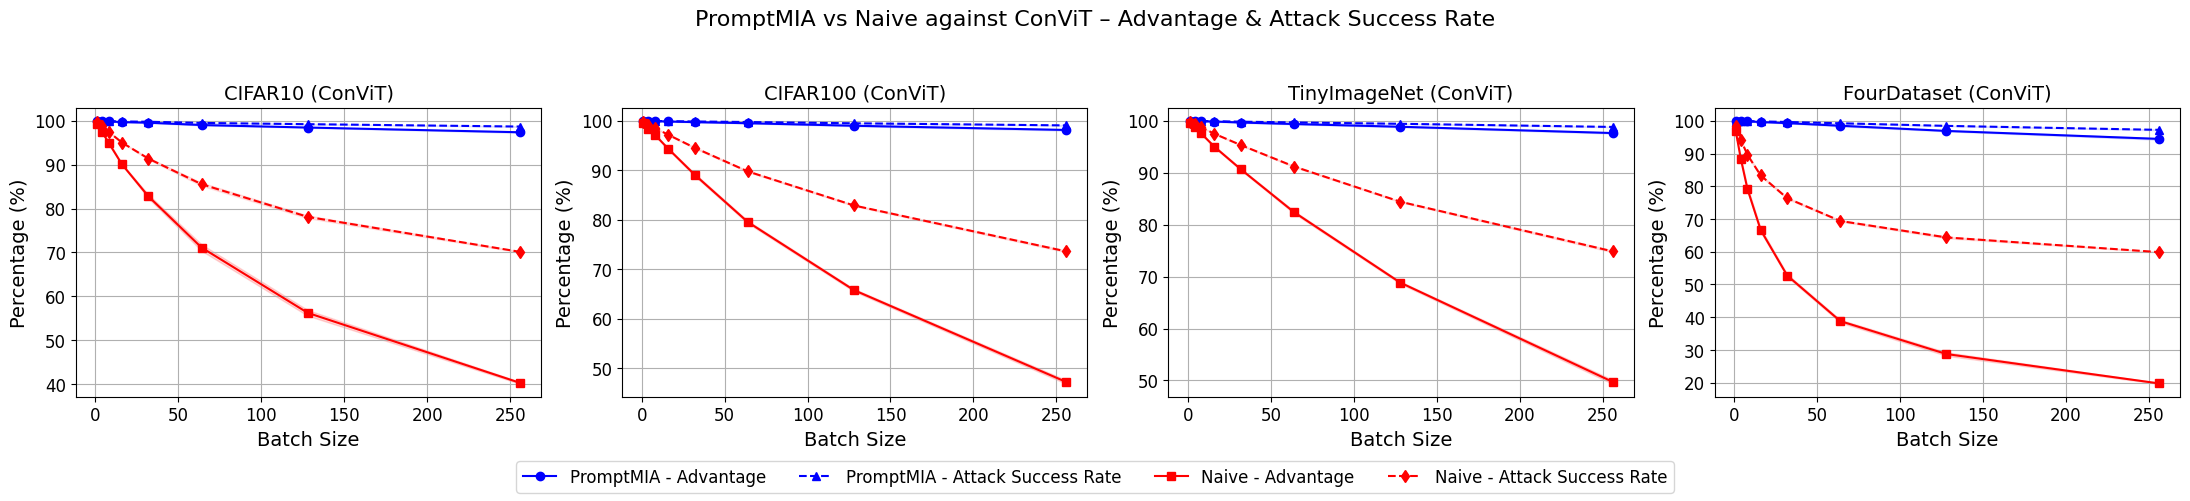

In [7]:

import re
from pathlib import Path
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
# ---------------- Regex patterns ----------------
BATCH_HEADER_RE = re.compile(r"=+\s*MIA with batch size\s+(\d+)\s*=+")
ADV_RE = re.compile(r"Advantage:\s*([0-9]*\.?[0-9]+)\s*%")
ACC_RE = re.compile(r"Attack Accuracy:\)\s*([0-9]*\.?[0-9]+)\s*%")

# ---------------- Parsing ----------------
def parse_log_file(path: str):
    text = Path(path).read_text(errors="ignore")

    adv_vals = defaultdict(list)
    acc_vals = defaultdict(list)

    headers = list(BATCH_HEADER_RE.finditer(text))
    if not headers:
        raise ValueError(f"No batch headers found in: {path}")

    for i, m in enumerate(headers):
        bs = int(m.group(1))
        start = m.end()
        end = headers[i + 1].start() if i + 1 < len(headers) else len(text)
        block = text[start:end]

        adv_m = ADV_RE.search(block)
        acc_m = ACC_RE.search(block)

        if adv_m:
            adv_vals[bs].append(float(adv_m.group(1)))
        if acc_m:
            acc_vals[bs].append(float(acc_m.group(1)))

    batches = sorted(set(adv_vals) & set(acc_vals))
    if not batches:
        raise ValueError(f"No valid batches in: {path}")

    adv_mean = [np.mean(adv_vals[b]) for b in batches]
    adv_std  = [np.std(adv_vals[b], ddof=0) for b in batches]
    acc_mean = [np.mean(acc_vals[b]) for b in batches]
    acc_std  = [np.std(acc_vals[b], ddof=0) for b in batches]

    return batches, adv_mean, adv_std, acc_mean, acc_std


def reindex(batches_src, arr_src, common_batches):
    idx = {b: i for i, b in enumerate(batches_src)}
    return [arr_src[idx[b]] for b in common_batches]


# ---------------- Pretty printing ----------------
def print_results(dataset_name, d):
    print(f"\n===== {dataset_name} (ConViT) =====")
    header = (
        "Batch | "
        "PromptMIA Adv (mean±std) | PromptMIA ASR (mean±std) | "
        "Naive Adv (mean±std) | Naive ASR (mean±std)"
    )
    print(header)
    print("-" * len(header))

    for i, b in enumerate(d["batch_sizes"]):
        print(
            f"{b:5d} | "
            f"{d['promptmia_adv'][i]:6.2f}±{d['promptmia_adv_std'][i]:5.2f} | "
            f"{d['promptmia_acc'][i]:6.2f}±{d['promptmia_acc_std'][i]:5.2f} | "
            f"{d['naive_adv'][i]:6.2f}±{d['naive_adv_std'][i]:5.2f} | "
            f"{d['naive_acc'][i]:6.2f}±{d['naive_acc_std'][i]:5.2f}"
        )


# ---------------- Main ----------------
def main():
    files = {
        "CIFAR10": {
            "promptmia": "/home/quannm/code/icml_promptmia/result_log/cifar10_convit_stealth.txt",
            "naive":     "/home/quannm/code/icml_promptmia/result_log/cifar10_convit_naive.txt",
        },
        "CIFAR100": {
            "promptmia": "/home/quannm/code/icml_promptmia/result_log/cifar100_convit_stealth.txt",
            "naive":     "/home/quannm/code/icml_promptmia/result_log/cifar100_convit_naive.txt",
        },
        "TinyImageNet": {
            "promptmia": "/home/quannm/code/icml_promptmia/result_log/tinyimagenet_convit_stealth.txt",
            "naive":     "/home/quannm/code/icml_promptmia/result_log/tinyimagenet_convit_naive.txt",
        },
        "FourDataset": {
            "promptmia": "/home/quannm/code/icml_promptmia/result_log/fourdataset_convit_stealth.txt",
            "naive":     "/home/quannm/code/icml_promptmia/result_log/fourdataset_convit_naive.txt",
        },
    }
    parsed = {}

    for name, paths in files.items():
        bs_p, adv_p, adv_p_std, acc_p, acc_p_std = parse_log_file(paths["promptmia"])
        bs_n, adv_n, adv_n_std, acc_n, acc_n_std = parse_log_file(paths["naive"])

        common_bs = sorted(set(bs_p) & set(bs_n))
        if not common_bs:
            raise ValueError(f"No overlapping batch sizes for {name}")

        parsed[name] = {
            "batch_sizes": common_bs,

            "promptmia_adv":     reindex(bs_p, adv_p, common_bs),
            "promptmia_adv_std": reindex(bs_p, adv_p_std, common_bs),
            "promptmia_acc":     reindex(bs_p, acc_p, common_bs),
            "promptmia_acc_std": reindex(bs_p, acc_p_std, common_bs),

            "naive_adv":         reindex(bs_n, adv_n, common_bs),
            "naive_adv_std":     reindex(bs_n, adv_n_std, common_bs),
            "naive_acc":         reindex(bs_n, acc_n, common_bs),
            "naive_acc_std":     reindex(bs_n, acc_n_std, common_bs),
        }

        # 🔹 Print numerical results
        print_results(name, parsed[name])

    # ---------------- Plot ----------------
    fig, axes = plt.subplots(1, 4, figsize=(22, 5))
    handles, labels = None, None

    for ax, (name, d) in zip(axes.flat, parsed.items()):
        bs = d["batch_sizes"]

        ax.plot(bs, d["promptmia_adv"], "o-", color="blue", label="PromptMIA - Advantage")
        ax.fill_between(
            bs,
            np.array(d["promptmia_adv"]) - np.array(d["promptmia_adv_std"]),
            np.array(d["promptmia_adv"]) + np.array(d["promptmia_adv_std"]),
            color="blue", alpha=0.15
        )

        ax.plot(bs, d["promptmia_acc"], "^--", color="blue", label="PromptMIA - Attack Success Rate")
        ax.fill_between(
            bs,
            np.array(d["promptmia_acc"]) - np.array(d["promptmia_acc_std"]),
            np.array(d["promptmia_acc"]) + np.array(d["promptmia_acc_std"]),
            color="blue", alpha=0.10
        )

        ax.plot(bs, d["naive_adv"], "s-", color="red", label="Naive - Advantage")
        ax.fill_between(
            bs,
            np.array(d["naive_adv"]) - np.array(d["naive_adv_std"]),
            np.array(d["naive_adv"]) + np.array(d["naive_adv_std"]),
            color="red", alpha=0.15
        )

        ax.plot(bs, d["naive_acc"], "d--", color="red", label="Naive - Attack Success Rate")
        ax.fill_between(
            bs,
            np.array(d["naive_acc"]) - np.array(d["naive_acc_std"]),
            np.array(d["naive_acc"]) + np.array(d["naive_acc_std"]),
            color="red", alpha=0.10
        )

        ax.set_title(f"{name} (ConViT)", fontsize=14)
        ax.set_xlabel("Batch Size", fontsize=14)
        ax.set_ylabel("Percentage (%)", fontsize=14)
        ax.yaxis.set_major_locator(MultipleLocator(10))
        ax.tick_params(axis="both", labelsize=12)
        ax.grid(True)

        if handles is None and labels is None:
            handles, labels = ax.get_legend_handles_labels()

    fig.legend(handles, labels, loc="lower center", fontsize=12, ncol=4)
    plt.suptitle(
        "PromptMIA vs Naive against ConViT – Advantage & Attack Success Rate",
        fontsize=16
    )
    plt.tight_layout(rect=[0, 0.07, 1, 0.93])
    plt.show()


if __name__ == "__main__":
    main()



===== CIFAR10 (DeiT) =====
Batch | PromptMIA Adv (mean±std) | PromptMIA ASR (mean±std) | Naive Adv (mean±std) | Naive ASR (mean±std)
---------------------------------------------------------------------------------------------------------
    1 | 100.00± 0.00 | 100.00± 0.00 |  99.58± 0.10 |  99.79± 0.05
    4 |  99.97± 0.02 |  99.98± 0.01 |  98.31± 0.08 |  99.15± 0.04
    8 |  99.93± 0.03 |  99.96± 0.01 |  96.57± 0.18 |  98.29± 0.09
   16 |  99.86± 0.03 |  99.93± 0.01 |  93.67± 0.17 |  96.84± 0.08
   32 |  99.75± 0.06 |  99.88± 0.03 |  88.16± 0.40 |  94.08± 0.20
   64 |  99.44± 0.07 |  99.72± 0.03 |  78.94± 0.43 |  89.47± 0.22
  128 |  99.06± 0.12 |  99.53± 0.06 |  65.78± 0.45 |  82.89± 0.22
  256 |  98.25± 0.12 |  99.13± 0.06 |  49.99± 0.83 |  75.00± 0.42

===== CIFAR100 (DeiT) =====
Batch | PromptMIA Adv (mean±std) | PromptMIA ASR (mean±std) | Naive Adv (mean±std) | Naive ASR (mean±std)
-------------------------------------------------------------------------------------------------

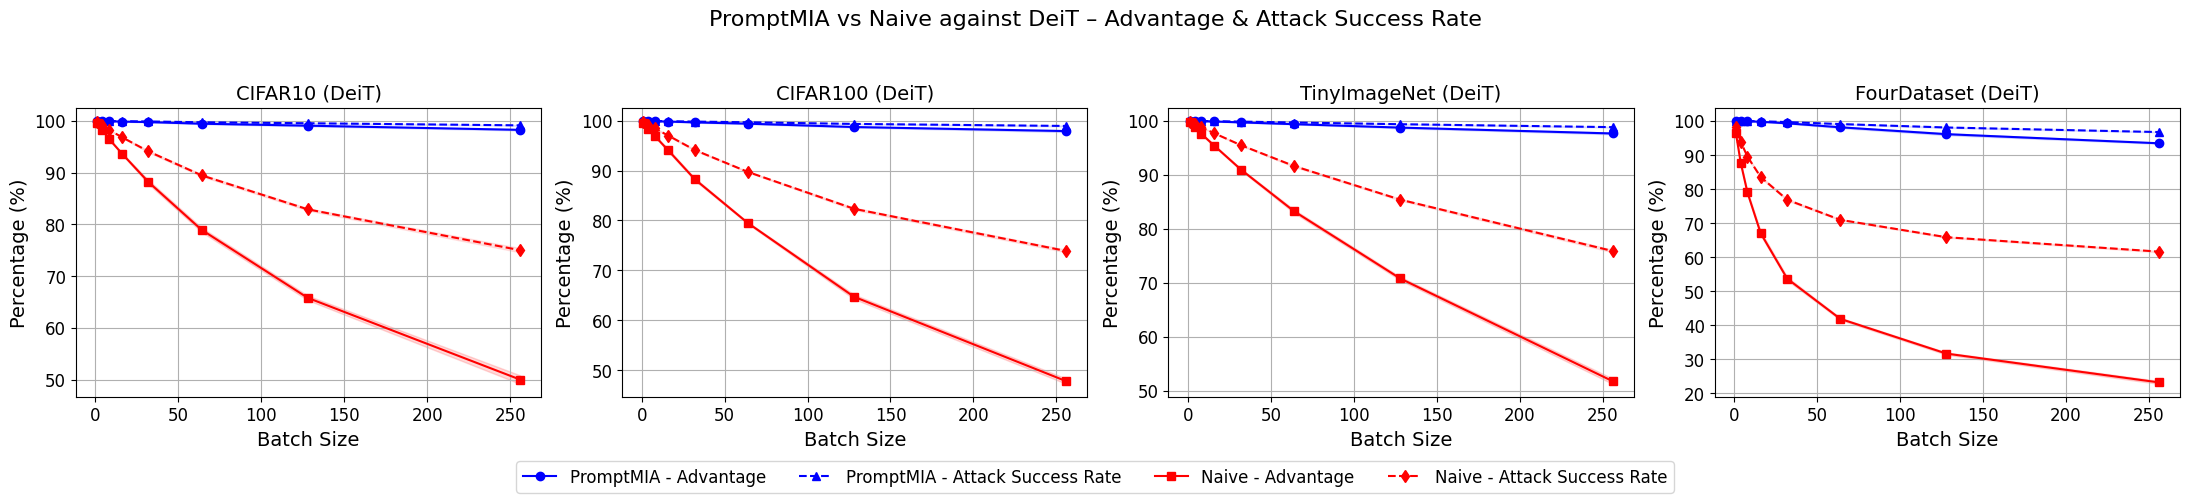

In [8]:

import re
from pathlib import Path
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
# ---------------- Regex patterns ----------------
BATCH_HEADER_RE = re.compile(r"=+\s*MIA with batch size\s+(\d+)\s*=+")
ADV_RE = re.compile(r"Advantage:\s*([0-9]*\.?[0-9]+)\s*%")
ACC_RE = re.compile(r"Attack Accuracy:\)\s*([0-9]*\.?[0-9]+)\s*%")

# ---------------- Parsing ----------------
def parse_log_file(path: str):
    text = Path(path).read_text(errors="ignore")

    adv_vals = defaultdict(list)
    acc_vals = defaultdict(list)

    headers = list(BATCH_HEADER_RE.finditer(text))
    if not headers:
        raise ValueError(f"No batch headers found in: {path}")

    for i, m in enumerate(headers):
        bs = int(m.group(1))
        start = m.end()
        end = headers[i + 1].start() if i + 1 < len(headers) else len(text)
        block = text[start:end]

        adv_m = ADV_RE.search(block)
        acc_m = ACC_RE.search(block)

        if adv_m:
            adv_vals[bs].append(float(adv_m.group(1)))
        if acc_m:
            acc_vals[bs].append(float(acc_m.group(1)))

    batches = sorted(set(adv_vals) & set(acc_vals))
    if not batches:
        raise ValueError(f"No valid batches in: {path}")

    adv_mean = [np.mean(adv_vals[b]) for b in batches]
    adv_std  = [np.std(adv_vals[b], ddof=0) for b in batches]
    acc_mean = [np.mean(acc_vals[b]) for b in batches]
    acc_std  = [np.std(acc_vals[b], ddof=0) for b in batches]

    return batches, adv_mean, adv_std, acc_mean, acc_std


def reindex(batches_src, arr_src, common_batches):
    idx = {b: i for i, b in enumerate(batches_src)}
    return [arr_src[idx[b]] for b in common_batches]


# ---------------- Pretty printing ----------------
def print_results(dataset_name, d):
    print(f"\n===== {dataset_name} (DeiT) =====")
    header = (
        "Batch | "
        "PromptMIA Adv (mean±std) | PromptMIA ASR (mean±std) | "
        "Naive Adv (mean±std) | Naive ASR (mean±std)"
    )
    print(header)
    print("-" * len(header))

    for i, b in enumerate(d["batch_sizes"]):
        print(
            f"{b:5d} | "
            f"{d['promptmia_adv'][i]:6.2f}±{d['promptmia_adv_std'][i]:5.2f} | "
            f"{d['promptmia_acc'][i]:6.2f}±{d['promptmia_acc_std'][i]:5.2f} | "
            f"{d['naive_adv'][i]:6.2f}±{d['naive_adv_std'][i]:5.2f} | "
            f"{d['naive_acc'][i]:6.2f}±{d['naive_acc_std'][i]:5.2f}"
        )


# ---------------- Main ----------------
def main():
    files = {
        "CIFAR10": {
            "promptmia": "/home/quannm/code/icml_promptmia/result_log/cifar10_deit_stealth.txt",
            "naive":     "/home/quannm/code/icml_promptmia/result_log/cifar10_deit_naive.txt",
        },
        "CIFAR100": {
            "promptmia": "/home/quannm/code/icml_promptmia/result_log/cifar100_deit_stealth.txt",
            "naive":     "/home/quannm/code/icml_promptmia/result_log/cifar100_deit_naive.txt",
        },
        "TinyImageNet": {
            "promptmia": "/home/quannm/code/icml_promptmia/result_log/tinyimagenet_deit_stealth.txt",
            "naive":     "/home/quannm/code/icml_promptmia/result_log/tinyimagenet_deit_naive.txt",
        },
        "FourDataset": {
            "promptmia": "/home/quannm/code/icml_promptmia/result_log/fourdataset_deit_stealth.txt",
            "naive":     "/home/quannm/code/icml_promptmia/result_log/fourdataset_deit_naive.txt",
        },
    }
    parsed = {}

    for name, paths in files.items():
        bs_p, adv_p, adv_p_std, acc_p, acc_p_std = parse_log_file(paths["promptmia"])
        bs_n, adv_n, adv_n_std, acc_n, acc_n_std = parse_log_file(paths["naive"])

        common_bs = sorted(set(bs_p) & set(bs_n))
        if not common_bs:
            raise ValueError(f"No overlapping batch sizes for {name}")

        parsed[name] = {
            "batch_sizes": common_bs,

            "promptmia_adv":     reindex(bs_p, adv_p, common_bs),
            "promptmia_adv_std": reindex(bs_p, adv_p_std, common_bs),
            "promptmia_acc":     reindex(bs_p, acc_p, common_bs),
            "promptmia_acc_std": reindex(bs_p, acc_p_std, common_bs),

            "naive_adv":         reindex(bs_n, adv_n, common_bs),
            "naive_adv_std":     reindex(bs_n, adv_n_std, common_bs),
            "naive_acc":         reindex(bs_n, acc_n, common_bs),
            "naive_acc_std":     reindex(bs_n, acc_n_std, common_bs),
        }

        # 🔹 Print numerical results
        print_results(name, parsed[name])

    # ---------------- Plot ----------------
    fig, axes = plt.subplots(1, 4, figsize=(22, 5))
    handles, labels = None, None

    for ax, (name, d) in zip(axes.flat, parsed.items()):
        bs = d["batch_sizes"]

        ax.plot(bs, d["promptmia_adv"], "o-", color="blue", label="PromptMIA - Advantage")
        ax.fill_between(
            bs,
            np.array(d["promptmia_adv"]) - np.array(d["promptmia_adv_std"]),
            np.array(d["promptmia_adv"]) + np.array(d["promptmia_adv_std"]),
            color="blue", alpha=0.15
        )

        ax.plot(bs, d["promptmia_acc"], "^--", color="blue", label="PromptMIA - Attack Success Rate")
        ax.fill_between(
            bs,
            np.array(d["promptmia_acc"]) - np.array(d["promptmia_acc_std"]),
            np.array(d["promptmia_acc"]) + np.array(d["promptmia_acc_std"]),
            color="blue", alpha=0.10
        )

        ax.plot(bs, d["naive_adv"], "s-", color="red", label="Naive - Advantage")
        ax.fill_between(
            bs,
            np.array(d["naive_adv"]) - np.array(d["naive_adv_std"]),
            np.array(d["naive_adv"]) + np.array(d["naive_adv_std"]),
            color="red", alpha=0.15
        )

        ax.plot(bs, d["naive_acc"], "d--", color="red", label="Naive - Attack Success Rate")
        ax.fill_between(
            bs,
            np.array(d["naive_acc"]) - np.array(d["naive_acc_std"]),
            np.array(d["naive_acc"]) + np.array(d["naive_acc_std"]),
            color="red", alpha=0.10
        )

        ax.set_title(f"{name} (DeiT)", fontsize=14)
        ax.set_xlabel("Batch Size", fontsize=14)
        ax.set_ylabel("Percentage (%)", fontsize=14)
        ax.yaxis.set_major_locator(MultipleLocator(10))
        ax.tick_params(axis="both", labelsize=12)
        ax.grid(True)

        if handles is None and labels is None:
            handles, labels = ax.get_legend_handles_labels()

    fig.legend(handles, labels, loc="lower center", fontsize=12, ncol=4)
    plt.suptitle(
        "PromptMIA vs Naive against DeiT – Advantage & Attack Success Rate",
        fontsize=16
    )
    plt.tight_layout(rect=[0, 0.07, 1, 0.93])
    plt.show()


if __name__ == "__main__":
    main()


In [9]:
import re
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
from matplotlib.ticker import MultipleLocator

FILE = "/home/quannm/code/icml_promptmia/result_log/avg.txt"

# Allow leading spaces + flexible equals count
HEADER_RE = re.compile(r"^\s*=+\s*([A-Za-z0-9]+)\s*\((ViT|ConViT|DeiT)\)\s*=+\s*$")
ROW_RE = re.compile(
    r"^\s*(\d+)\s*\|\s*"          # batch
    r"([\d.]+)±[\d.]+\s*\|\s*"    # PromptMIA Adv
    r"([\d.]+)±[\d.]+\s*\|\s*"    # PromptMIA ASR
    r"([\d.]+)±[\d.]+\s*\|\s*"    # Naive Adv
    r"([\d.]+)±[\d.]+"            # Naive ASR
)

data = defaultdict(lambda: defaultdict(list))
current_dataset = None

with open(FILE, "r") as f:
    for line in f:
        h = HEADER_RE.match(line)
        if h:
            current_dataset = h.group(1).strip()  # e.g., CIFAR10
            continue

        r = ROW_RE.match(line)
        if r and current_dataset is not None:
            b = int(r.group(1))
            vals = list(map(float, r.groups()[1:]))  # [PM Adv, PM ASR, Naive Adv, Naive ASR]
            data[current_dataset][b].append(vals)

# Average over (ViT, ConViT, DeiT)
avg = {}
for ds, batches in data.items():
    avg[ds] = {}
    for b, rows in batches.items():
        avg[ds][b] = np.mean(rows, axis=0)

print("Parsed datasets:", sorted(avg.keys()))

# Plot in your preferred order (only if present)
order = ["CIFAR10", "CIFAR100", "TinyImageNet", "FourDataset"]
present = [ds for ds in order if ds in avg]

fig, axes = plt.subplots(1, len(present), figsize=(5.5 * len(present), 5))
if len(present) == 1:
    axes = [axes]

for ax, ds in zip(axes, present):
    batches = sorted(avg[ds].keys())
    vals = np.array([avg[ds][b] for b in batches])

    ax.plot(batches, vals[:, 0], "o-", label="PromptMIA - Advantage")
    ax.plot(batches, vals[:, 1], "^--", label="PromptMIA - ASR")
    ax.plot(batches, vals[:, 2], "s-", label="Naive - Advantage")
    ax.plot(batches, vals[:, 3], "d--", label="Naive - ASR")

    ax.set_title(f"{ds} (avg ViT/ConViT/DeiT)", fontsize=13)
    ax.set_xlabel("Batch Size")
    ax.set_ylabel("Percentage (%)")
    ax.yaxis.set_major_locator(MultipleLocator(10))
    ax.grid(True)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, fontsize=11)

plt.suptitle("PromptMIA vs Naive – Average over ViT / ConViT / DeiT", fontsize=15)
plt.tight_layout(rect=[0, 0.08, 1, 0.93])
plt.show()


Parsed datasets: []


ValueError: Number of columns must be a positive integer, not 0

<Figure size 0x500 with 0 Axes>